# Лабораторная работа 4. Многомерная бинарная классификация

Датасет: `datasets/student.csv`. Предсказываем `G3`.

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [34]:
df = pd.read_csv('student.csv')
df = df.drop('Unnamed: 0', axis=1)
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,no,no,4,3,4,1,1,3,6,0
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,yes,no,5,3,3,1,1,3,4,0
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,yes,no,4,3,2,2,3,3,10,0
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,yes,3,2,2,1,1,5,2,1
4,GP,F,16,U,GT3,T,3,3,other,other,...,no,no,4,3,2,1,2,5,4,0


In [35]:
df['G3'].nunique()

2

# Задание 1
Предобработайте данные. Для числовых признаков используйте стандартизацию, для категориальных - one-hot-кодирование. Разделите выборку на обучающую и тестовую. Размер выборок выберите самостоятельно.

In [36]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

X = df.drop('G3', axis=1)
y = df['G3']

num_cols = [
    "age", "Medu", "Fedu", "traveltime", "studytime", "failures",
    "famrel", "freetime", "goout", "Dalc", "Walc", "health", "absences"
]
cat_cols = [
    "school", "sex", "address", "famsize", "Pstatus",
    "Mjob", "Fjob", "reason", "guardian",
    "schoolsup", "famsup", "paid", "activities", "nursery",
    "higher", "internet", "romantic"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ]
)

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=42)

In [37]:
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_prep_df = pd.DataFrame(
    X_train_prep,
    columns=feature_names,
    index=X_train.index
)

X_test_prep_df = pd.DataFrame(
    X_test_prep,
    columns=feature_names,
    index=X_test.index
)

In [38]:
X_train_prep_df.head()

,num__age,num__Medu,num__Fedu,num__traveltime,num__studytime,num__failures,num__famrel,num__freetime,num__goout,num__Dalc,...,cat__activities_no,cat__activities_yes,cat__nursery_no,cat__nursery_yes,cat__higher_no,cat__higher_yes,cat__internet_no,cat__internet_yes,cat__romantic_no,cat__romantic_yes
181,-0.586396,0.246437,0.423207,-0.625779,-0.056853,-0.456744,0.064432,-1.195981,-0.144396,-0.55443,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0
194,-0.586396,-0.680636,0.423207,0.828236,-1.254553,-0.456744,1.195575,-0.214345,-0.144396,-0.55443,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
173,-0.586396,-1.607709,0.423207,-0.625779,-0.056853,3.628097,0.064432,-0.214345,1.644982,-0.55443,...,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
63,-0.586396,1.173510,0.423207,-0.625779,1.140847,-0.456744,-1.066710,0.767292,0.750293,0.55443,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
253,-0.586396,-0.680636,-1.434203,0.828236,-1.254553,-0.456744,-1.066710,-0.214345,-1.039085,-0.55443,...,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0


# Задание 2

Обучите следующие модели:
1. SVM
2. Логистическая регрессия
3. KNN
4. Дерево решений

Подберите оптимальные гиперпараметры с помощью кросс-валидации

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [70]:
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

svm_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'kernel': ['linear', 'poly'],
    'class_weight': [None, 'balanced']
}
svm_grid = GridSearchCV(
    estimator=SVC(probability=True),
    param_grid=svm_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    refit=True
)
svm_grid.fit(X_train_prep, y_train)
best_model_svm = svm_grid.best_estimator_
y_pred_svm = best_model_svm.predict(X_test_prep)
y_proba_svm = best_model_svm.predict_proba(X_test_prep)[:, 1]

print('SVM:', svm_grid.best_params_, svm_grid.best_score_)

SVM: {'C': 0.1, 'class_weight': None, 'kernel': 'linear'} 0.7154570041182617


In [71]:
log_params = {
    'C': [0.01, 0.1, 1, 10, 100],
    'class_weight': [None, 'balanced']
}
log_grid = GridSearchCV(
    LogisticRegression(max_iter=5000, solver='lbfgs'),
    log_params, scoring='roc_auc', cv=cv, n_jobs=-1, refit=True
)
log_grid.fit(X_train_prep, y_train)
best_model_log = log_grid.best_estimator_
y_pred_log = best_model_log.predict(X_test_prep)
y_proba_log = best_model_log.predict_proba(X_test_prep)[:, 1]

print('LOG:', log_grid.best_params_, log_grid.best_score_)

LOG: {'C': 0.1, 'class_weight': 'balanced'} 0.7060401171963038


In [78]:
knn_params = {
    'n_neighbors': [3, 5, 7, 11, 15, 21],
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}
knn_grid = GridSearchCV(
    KNeighborsClassifier(), knn_params,
    scoring='roc_auc', cv=cv, n_jobs=-1, refit=True
)
knn_grid.fit(X_train_prep, y_train)
best_model_knn = knn_grid.best_estimator_
y_pred_knn = best_model_knn.predict(X_test_prep)
y_proba_knn = best_model_knn.predict_proba(X_test_prep)[:, 1]

print('KNN:', knn_grid.best_params_, knn_grid.best_score_)

KNN: {'n_neighbors': 7, 'p': 2, 'weights': 'distance'} 0.6418892781773107


In [79]:
tree_params = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_leaf': [1, 3, 5, 10],
    'criterion': ['gini', 'entropy'],
    'class_weight': [None, 'balanced']
}
tree_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42), tree_params,
    scoring='roc_auc', cv=cv, n_jobs=-1, refit=True
)
tree_grid.fit(X_train_prep, y_train)
best_model_tree = tree_grid.best_estimator_
y_pred_tree = best_model_tree.predict(X_test_prep)
y_proba_tree = best_model_tree.predict_proba(X_test_prep)[:, 1]

print('TREE:', tree_grid.best_params_, tree_grid.best_score_)

TREE: {'class_weight': None, 'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 1} 0.6593523469994058


# Задание 3

Для каждой модели посчитайте Accuracy, Precision, Recall, F1-score. Постройте confusion matrix и roc-кривую.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

def get_metrics(name, y_true, y_pred):
    return {
        'model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
    }

results = [
    get_metrics('SVM', y_test, y_pred_svm),
    get_metrics('Logistic Regression', y_test, y_pred_log),
    get_metrics('KNN', y_test, y_pred_knn),
    get_metrics('Decision Tree', y_test, y_pred_tree),
]

df_metrics = pd.DataFrame(results).set_index('model')
df_metrics

,Accuracy,Precision,Recall,F1
model,,,,
SVM,0.670886,0.647059,0.804878,0.717391
Logistic Regression,0.632911,0.636364,0.682927,0.658824
KNN,0.582278,0.576923,0.731707,0.645161
Decision Tree,0.569620,0.563636,0.756098,0.645833


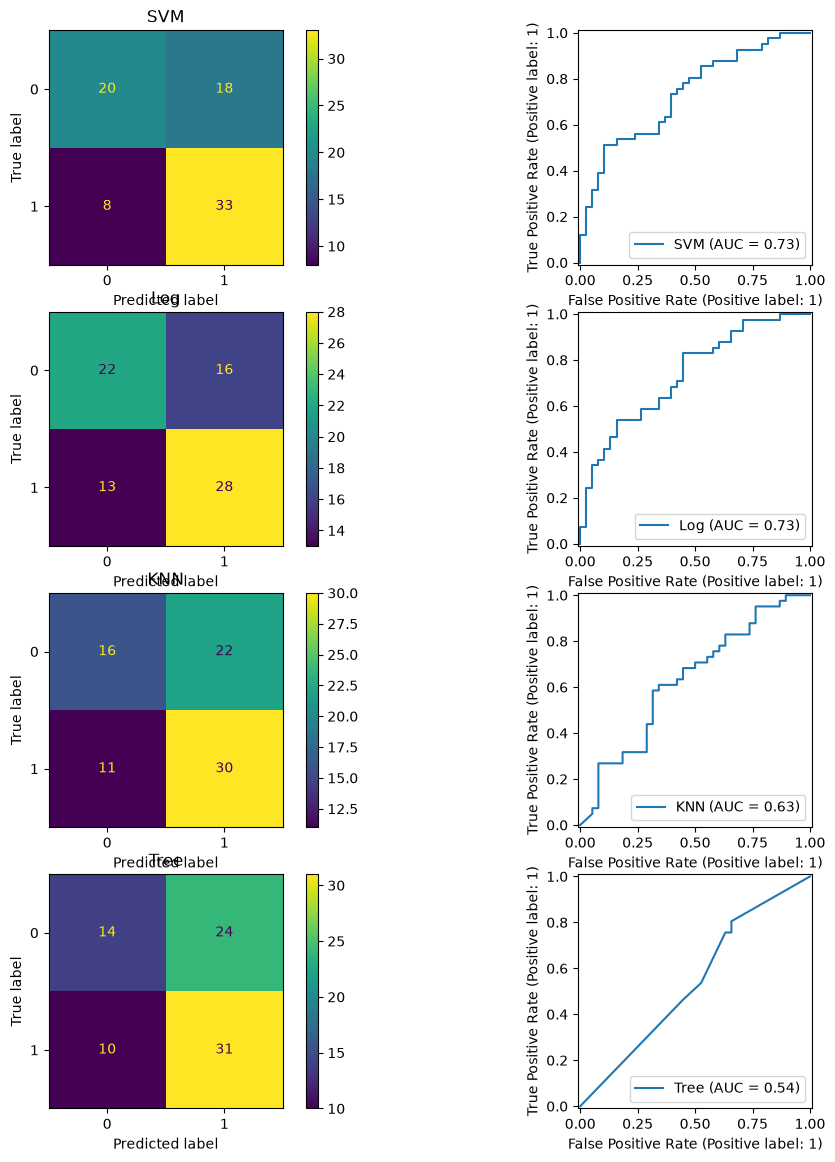

In [83]:
figs, axes = plt.subplots(4, 2, figsize=(13, 14))
models = [
    ('SVM', y_pred_svm, y_proba_svm), 
    ('Log', y_pred_log, y_proba_log), 
    ('KNN', y_pred_knn, y_proba_knn), 
    ('Tree', y_pred_tree, y_proba_tree),
]

for i in range(4):
    axes[i][0].set_title(models[i][0])
    ConfusionMatrixDisplay.from_predictions(y_test, models[i][1], ax=axes[i][0])
    RocCurveDisplay.from_predictions(y_test, models[i][2], ax=axes[i][1], name=models[i][0])

plt.show()

# Задание 4

Для логистической регрессии выберите оптимальный порог классификации. Постройте график зависимости метрик от порога классификации. Сравнить качество модели при оптимальном пороге и пороге равном 0.5.

Лучший порог по F1: 0.320, F1 = 0.7407


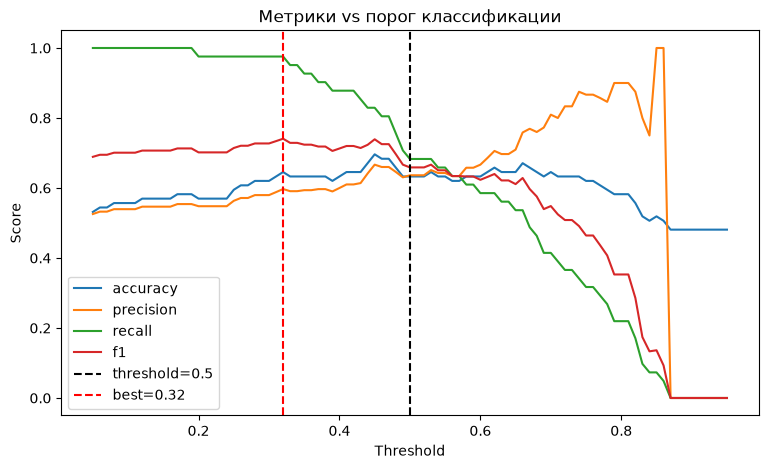

threshold = 0.500: acc=0.6329, prec=0.6364, rec=0.6829, f1=0.6588
threshold = 0.320: acc=0.6456, prec=0.5970, rec=0.9756, f1=0.7407


In [ ]:
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score

y_proba = best_model_log.predict_proba(X_test_prep)[:, 1]

thresholds = np.linspace(0.05, 0.95, 91)
metrics = {'accuracy': [], 'precision': [], 'recall': [], 'f1': []}

for t in thresholds:
    y_pred_t = (y_proba >= t).astype(int)
    metrics['accuracy'].append(accuracy_score(y_test, y_pred_t))
    metrics['precision'].append(precision_score(y_test, y_pred_t, zero_division=0))
    metrics['recall'].append(recall_score(y_test, y_pred_t, zero_division=0))
    metrics['f1'].append(f1_score(y_test, y_pred_t, zero_division=0))

best_idx = int(np.argmax(metrics['f1']))
best_thr = thresholds[best_idx]
print(f'Лучший порог по F1: {best_thr:.3f}, F1 = {metrics["f1"][best_idx]:.4f}')

plt.figure(figsize=(9, 5))
for k, v in metrics.items():
    plt.plot(thresholds, v, label=k)
plt.axvline(0.5, color='k', linestyle='--', label='threshold=0.5')
plt.axvline(best_thr, color='r', linestyle='--', label=f'best={best_thr:.2f}')
plt.xlabel('Threshold'); plt.ylabel('Score'); plt.legend()
plt.title('Метрики vs порог классификации')
plt.show()

for t in [0.5, best_thr]:
    y_pred_t = (y_proba >= t).astype(int)
    print(f'threshold = {t:.3f}: '
          f'acc={accuracy_score(y_test, y_pred_t):.4f}, '
          f'prec={precision_score(y_test, y_pred_t, zero_division=0):.4f}, '
          f'rec={recall_score(y_test, y_pred_t, zero_division=0):.4f}, '
          f'f1={f1_score(y_test, y_pred_t, zero_division=0):.4f}')